# CEBRA Latents

Creates a latent representation of the preprocessed LFP using CEBRA.

CEBRA is a contrastive learning method that maps high-dimensional neural signals into a low-dimensional latent space. Here it is trained in self-supervised mode (CEBRA-Time), so it learns from the temporal structure of the LFP without using any position labels.

- Trained on the training split only
- Used to encode every trial (train, validation and test)

**Input:** `data/processed/raw_lfp/`  
**Output:** `data/processed/cebra_latents/`

## Setup

In [4]:
from pathlib import Path
import json, warnings
warnings.filterwarnings('ignore', message='.*torch.jit.script.*', category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import cebra

plt.rcParams['figure.dpi'] = 110
print('cebra', cebra.__version__, '| torch', torch.__version__)

cebra 0.6.1 | torch 2.14.1


## Paths

In [5]:
# Repository root: the first folder above this notebook that contains pyproject.toml
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())

INPUT_ROOT  = REPO / 'data' / 'processed' / 'raw_lfp'        # written by preprocess_raw_lfp.ipynb
OUTPUT_ROOT = REPO / 'data' / 'processed' / 'cebra_latents'  # one output subfolder per rat

SESSIONS = sorted(p.name for p in INPUT_ROOT.iterdir() if (p / 'position_decoding.npz').is_file())
print('Input: ', INPUT_ROOT)
print('Output:', OUTPUT_ROOT)
print('Rats:  ', SESSIONS)

Input:  /Users/anthonyko/UCI Capstone/hippocampal-representation-learning/data/processed/raw_lfp
Output: /Users/anthonyko/UCI Capstone/hippocampal-representation-learning/data/processed/cebra_latents
Rats:   ['080718_mitt', '081106_barat', '090212_stella', '090212_superchris', '090420_buchanan']


## Load preprocessed data

Each rat's trials, with their train / validation / test split. CEBRA will be fitted on the training trials only.

In [6]:
def load_session(session):
    """Preprocessed trials for one rat. Position labels are kept separate and never used to fit CEBRA."""
    with np.load(INPUT_ROOT / session / 'position_decoding.npz', allow_pickle=False) as d:
        return dict(X=d['X'].astype(np.float32),        # trials x samples x channels
                    y=d['y'],                           # position 0-4
                    trial_ids=d['trial_ids'],
                    split=d['split'].astype(str))


data = {session: load_session(session) for session in SESSIONS}
display(pd.DataFrame([dict(rat=s, trials=len(d['X']), samples=d['X'].shape[1], channels=d['X'].shape[2],
                           train=(d['split'] == 'train').sum(), validation=(d['split'] == 'validation').sum(),
                           test=(d['split'] == 'test').sum())
                      for s, d in data.items()]).set_index('rat'))

,trials,samples,channels,train,validation,test
rat,,,,,,
080718_mitt,249,500,22,167,47,35
081106_barat,154,500,22,111,24,19
090212_stella,190,500,21,150,28,12
090212_superchris,187,500,21,138,31,18
090420_buchanan,208,500,20,174,19,15


## CEBRA settings

The same settings are used for every rat.

| Setting | Value | Why |
|---|---|---|
| `model_architecture` | `offset10-model` | Each output sample is computed from a 10 ms stretch of LFP: short enough to stay within one trial, long enough to capture fast fluctuations. |
| `output_dimension` | 8 | A compact latent space, much smaller than the 20–22 channels, which is a common starting size for CEBRA. |
| `conditional` | `'time'` | CEBRA-Time learns only from timing in the signal, with no labels, so the latents cannot simply memorize position. |
| `time_offsets` | 10 | Samples 10 ms apart are treated as similar (a positive pair); samples from elsewhere in the batch are treated as different. |
| `distance`, `temperature` | cosine, 1.0 | CEBRA's standard choices for CEBRA-Time. |
| `batch_size` | 512 | Samples compared per training update; more samples give more contrast for the loss. |
| `learning_rate` | 3e-4 | CEBRA's default step size. |
| `max_iterations` | 1000 | A quick first pass. The loss was still falling at 1000 updates, so longer training is a possible improvement. |
| `device` | `'cpu'` | No GPU is needed for data this size, and CPU runs are easier to repeat exactly. |
| `SEED` | 42 | Any fixed number works; fixing it makes reruns give similar models. |

In [7]:
CEBRA_PARAMS = dict(
    model_architecture='offset10-model',  # each output sample sees a 10 ms window of LFP
    output_dimension=8,                   # number of latent dimensions
    conditional='time',                   # CEBRA-Time: self-supervised, no labels
    time_offsets=10,                      # positive pair = a sample 10 ms later
    distance='cosine',
    temperature=1.0,
    batch_size=512,
    learning_rate=3e-4,
    max_iterations=1000,
    device='cpu',
    verbose=False,
)
SEED = 42
CEBRA_PARAMS

{'model_architecture': 'offset10-model',
 'output_dimension': 8,
 'conditional': 'time',
 'time_offsets': 10,
 'distance': 'cosine',
 'temperature': 1.0,
 'batch_size': 512,
 'learning_rate': 0.0003,
 'max_iterations': 1000,
 'device': 'cpu',
 'verbose': False}

## Train CEBRA

One model per rat, fitted on that rat's **training trials only**. Validation and test trials are never seen during training, and no labels are used.

**Why one model per rat:** rats have different numbers and placements of channels (20–22), so their inputs are not comparable.
**Why training trials only:** fitting CEBRA on the whole session would let held-out trials shape the latent space, which leaks information into the test scores.

In [8]:
def fit_cebra(X_train):
    """Fit CEBRA-Time on training trials only, joined end to end in time order."""
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    model = cebra.CEBRA(**CEBRA_PARAMS)
    model.fit(X_train.reshape(-1, X_train.shape[-1]))   # (trials * samples) x channels
    return model


models, losses = {}, {}
for session, d in data.items():
    X_train = d['X'][d['split'] == 'train']
    models[session] = fit_cebra(X_train)
    losses[session] = models[session].state_dict_['loss'].tolist()   # one value per update
    print(f'{session}: fit on {len(X_train)} training trials, final loss {losses[session][-1]:.3f}')

080718_mitt: fit on 167 training trials, final loss 5.596
081106_barat: fit on 111 training trials, final loss 5.563
090212_stella: fit on 150 training trials, final loss 5.620
090212_superchris: fit on 138 training trials, final loss 5.635
090420_buchanan: fit on 174 training trials, final loss 5.516


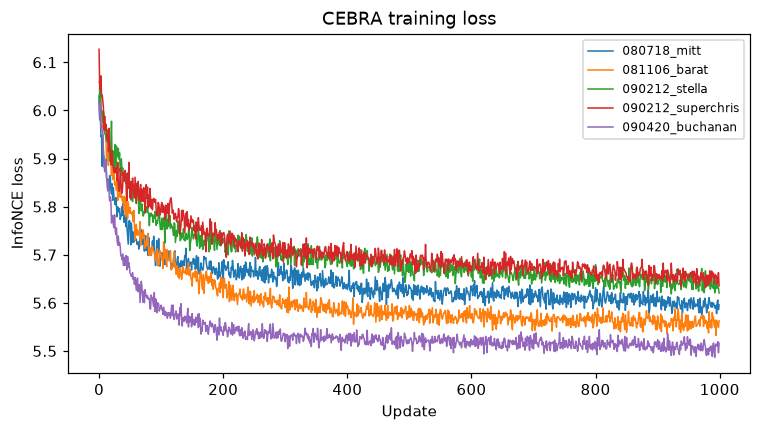

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
for session, loss in losses.items():
    ax.plot(loss, lw=1, label=session)
ax.set(xlabel='Update', ylabel='InfoNCE loss', title='CEBRA training loss')
ax.legend(fontsize=8)
plt.show()

## Encode all trials

Every trial (train, validation and test) is passed through its rat's trained model. Each trial is encoded on its own.

**Why one trial at a time:** the model looks at a 10 ms window around each sample. Encoding trials separately keeps that window from reaching into the neighboring trial.

In [10]:
def encode_trials(model, X):
    """Encode each trial on its own, so no context window spans two trials."""
    return np.stack([model.transform(trial) for trial in X]).astype(np.float32)


latents = {}
for session, d in data.items():
    latents[session] = encode_trials(models[session], d['X'])     # trials x samples x latent dims
    print(f'{session}: latents {latents[session].shape}')

080718_mitt: latents (249, 500, 8)
081106_barat: latents (154, 500, 8)
090212_stella: latents (190, 500, 8)
090212_superchris: latents (187, 500, 8)
090420_buchanan: latents (208, 500, 8)


## Save latents

Saves, for each rat:
- `cebra_latents.npz`: `Z` (trials × samples × latent dims), `trial_ids` and `split`, in the same order as the preprocessed data
- `cebra_model.pt`: the trained model, so it can be reloaded without retraining
- `cebra_config.json`: the settings used

In [11]:
OVERWRITE = False   # refuse to overwrite saved latents

existing = [s for s in SESSIONS if (OUTPUT_ROOT / s).exists()]
if existing and not OVERWRITE:
    raise FileExistsError(f'Latents already saved for {existing}; delete them or set OVERWRITE = True')

for session, d in data.items():
    out = OUTPUT_ROOT / session
    out.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(out / 'cebra_latents.npz', Z=latents[session],
                        trial_ids=d['trial_ids'], split=d['split'])
    models[session].save(str(out / 'cebra_model.pt'))
    (out / 'cebra_config.json').write_text(json.dumps(dict(
        params=CEBRA_PARAMS, seed=SEED, cebra_version=cebra.__version__, torch_version=torch.__version__,
        fit_split='train', fit_trials=int((d['split'] == 'train').sum()),
        final_loss=losses[session][-1]), indent=2) + '\n')
    print(f'{session}: saved to {out}')

080718_mitt: saved to /Users/anthonyko/UCI Capstone/hippocampal-representation-learning/data/processed/cebra_latents/080718_mitt
081106_barat: saved to /Users/anthonyko/UCI Capstone/hippocampal-representation-learning/data/processed/cebra_latents/081106_barat
090212_stella: saved to /Users/anthonyko/UCI Capstone/hippocampal-representation-learning/data/processed/cebra_latents/090212_stella
090212_superchris: saved to /Users/anthonyko/UCI Capstone/hippocampal-representation-learning/data/processed/cebra_latents/090212_superchris
090420_buchanan: saved to /Users/anthonyko/UCI Capstone/hippocampal-representation-learning/data/processed/cebra_latents/090420_buchanan


## What is CEBRA capturing?

A low training loss does not mean the latents carry position information. These plots check what the latents follow:
- **Colored by position:** separate clusters would suggest position-related structure.
- **Colored by trial order:** a smooth color gradient means the latents track slow drift across the session.
- **Colored by split:** validation and test trials should overlap the training trials.

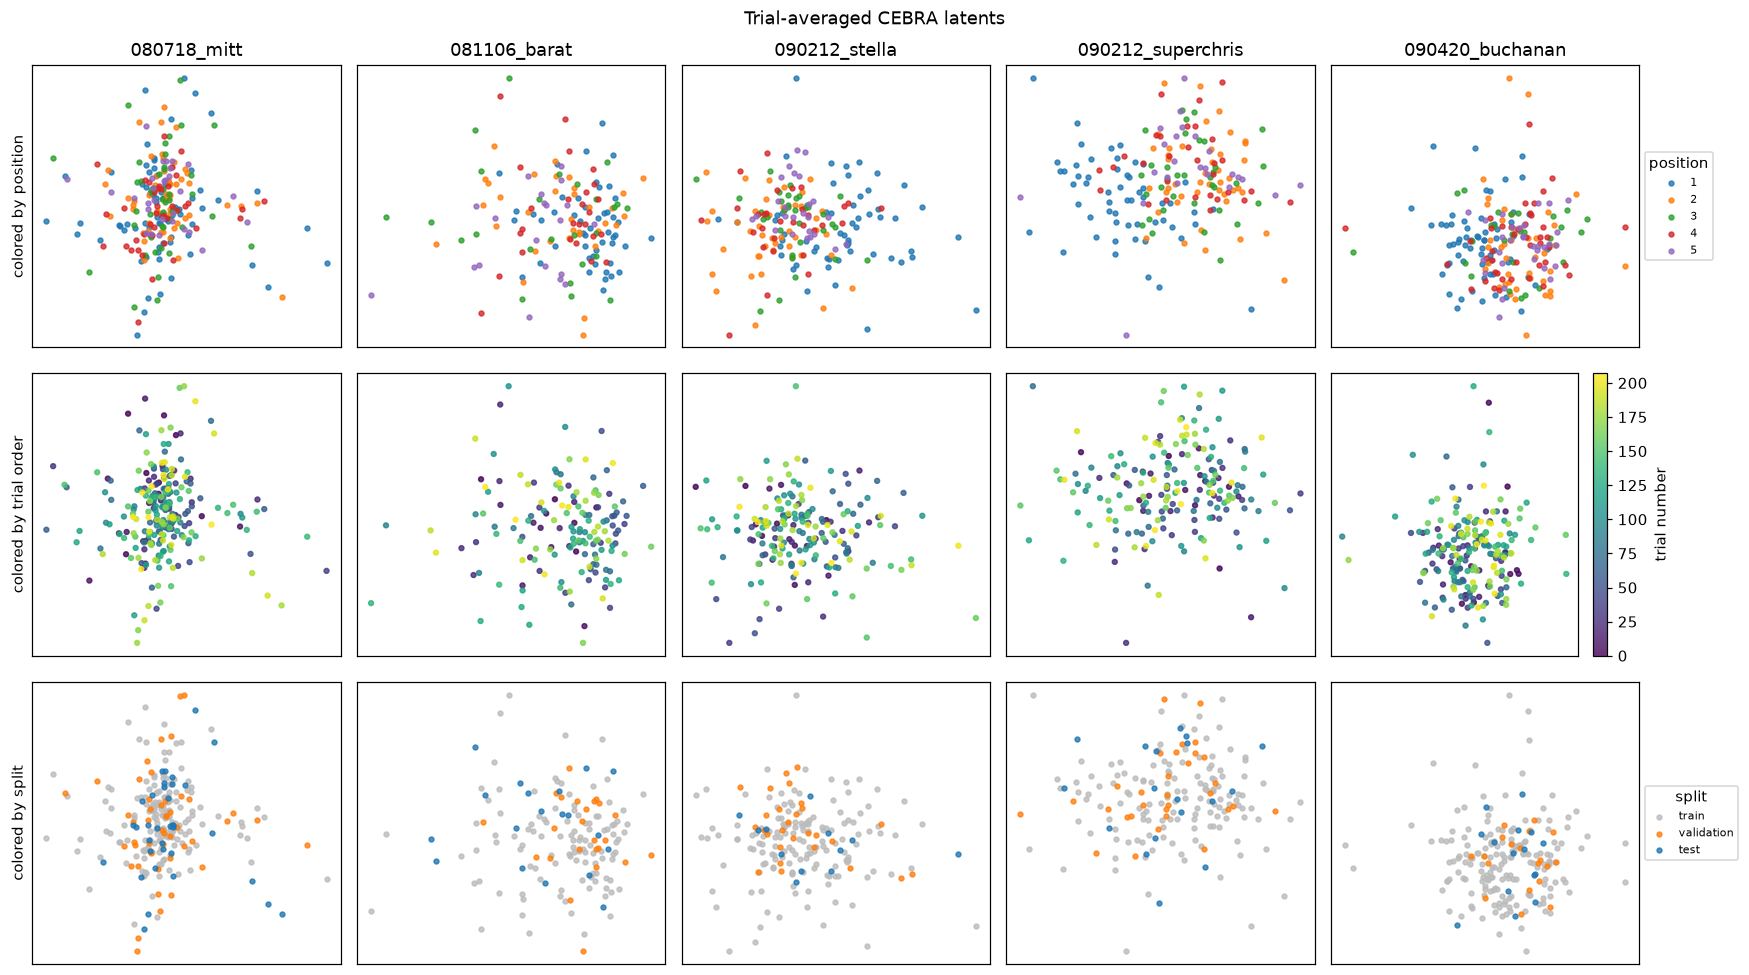

In [14]:
from sklearn.decomposition import PCA

# Each dot is one trial: its latents averaged over the 500 ms, projected onto 2 PCs fitted on training trials.
POSITION_COLORS = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']   # positions 1-5
SPLIT_COLORS = {'train': '#bbbbbb', 'validation': '#ff7f0e', 'test': '#1f77b4'}

fig, axes = plt.subplots(3, len(SESSIONS), figsize=(3.2 * len(SESSIONS), 9), squeeze=False)
for col, session in enumerate(SESSIONS):
    d, Z = data[session], latents[session]
    means = Z.mean(axis=1)
    train = d['split'] == 'train'
    xy = PCA(n_components=2).fit(means[train]).transform(means)

    ax = axes[0, col]                                   # row 1: position
    for pos in range(5):
        sel = d['y'] == pos
        ax.scatter(xy[sel, 0], xy[sel, 1], s=10, alpha=.8, color=POSITION_COLORS[pos], label=str(pos + 1))

    ax = axes[1, col]                                   # row 2: trial order
    sc = ax.scatter(xy[:, 0], xy[:, 1], c=np.arange(len(means)), cmap='viridis', s=10, alpha=.8)

    ax = axes[2, col]                                   # row 3: split
    for split, color in SPLIT_COLORS.items():
        sel = d['split'] == split
        ax.scatter(xy[sel, 0], xy[sel, 1], s=10, alpha=.8, color=color, label=split)

    for row in range(3):
        axes[row, col].set(xticks=[], yticks=[], title=session if row == 0 else '')

for row, name in enumerate(['position', 'trial order', 'split']):
    axes[row, 0].set_ylabel(f'colored by {name}')
axes[0, -1].legend(title='position', fontsize=7, loc='center left', bbox_to_anchor=(1, .5))
fig.colorbar(sc, ax=axes[1, -1], label='trial number')
axes[2, -1].legend(title='split', fontsize=7, loc='center left', bbox_to_anchor=(1, .5))
fig.suptitle('Trial-averaged CEBRA latents')
plt.tight_layout()
plt.show()

Average latent time course after odor onset, one line per position. Lines that separate suggest the latents differ by position.

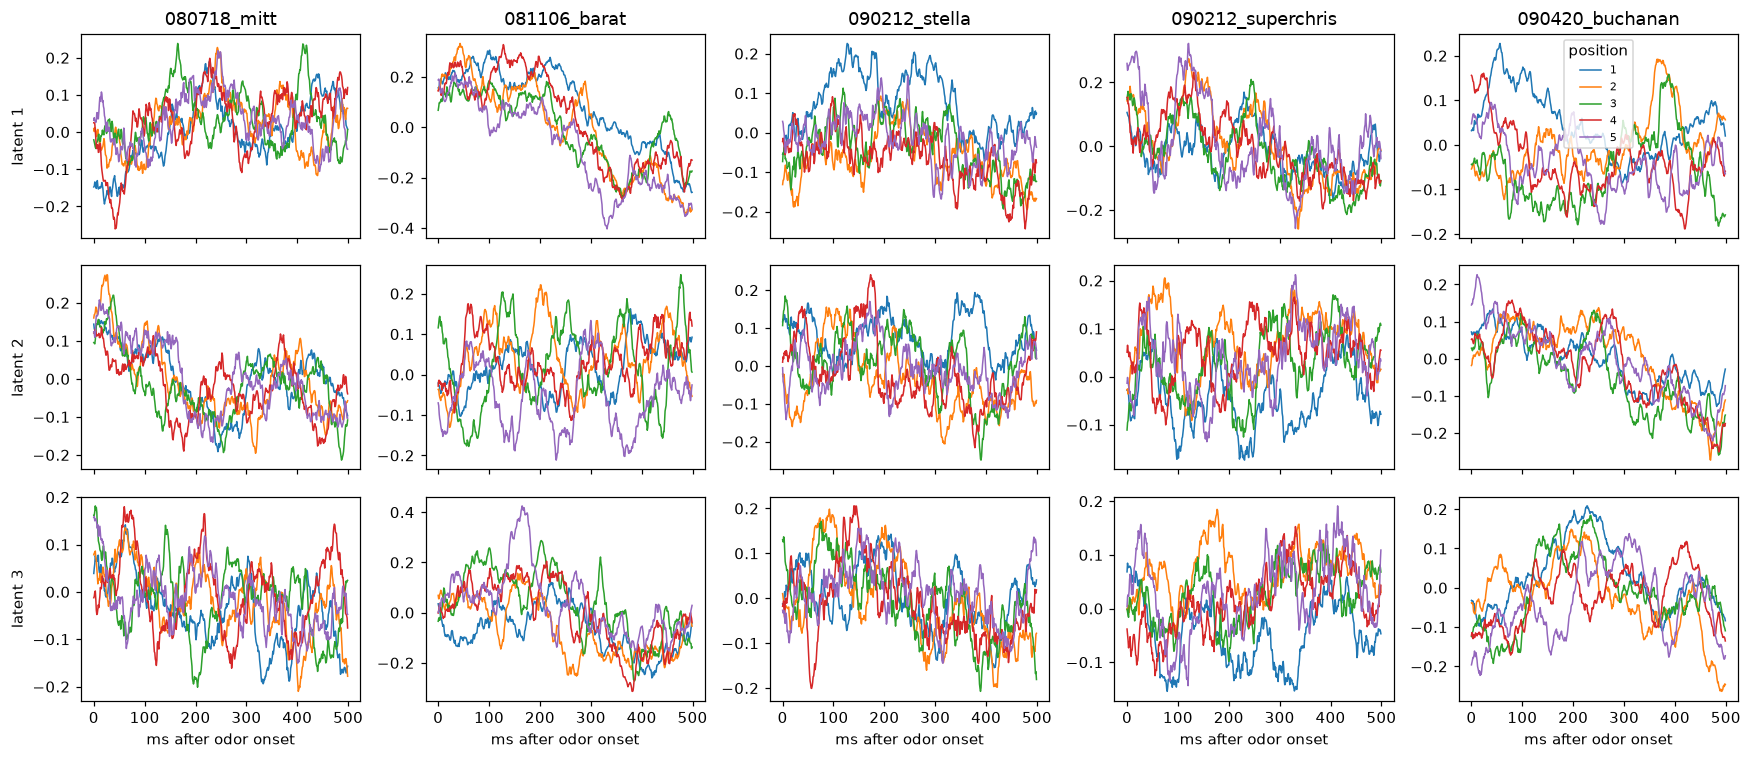

In [15]:
# Average latent time course for each position, training trials only, first 3 latent dimensions.
fig, axes = plt.subplots(3, len(SESSIONS), figsize=(3.2 * len(SESSIONS), 7), sharex=True, squeeze=False)
t_ms = np.arange(next(iter(latents.values())).shape[1])
for col, session in enumerate(SESSIONS):
    d, Z = data[session], latents[session]
    train = d['split'] == 'train'
    for dim in range(3):
        ax = axes[dim, col]
        for pos in range(5):
            sel = train & (d['y'] == pos)
            ax.plot(t_ms, Z[sel, :, dim].mean(axis=0), lw=1, label=str(pos + 1))
        ax.set(title=session if dim == 0 else '')
        if col == 0:
            ax.set_ylabel(f'latent {dim + 1}')
        if dim == 2:
            ax.set_xlabel('ms after odor onset')
axes[0, -1].legend(title='position', fontsize=7)
plt.tight_layout()
plt.show()